In [ ]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target

print(X.shape)
print(y.shape)
print(data.target_names)

(569, 30)
(569,)
['malignant' 'benign']


In [ ]:
data.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

In [ ]:
import pandas as pd

# Convert the scikit-learn Bunch object into a pandas DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
# Add the target column
df['target'] = data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X,y, random_state=42, test_size=0.2)

print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(455, 30)
(114, 30)
(455,)
(114,)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression())
])

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('clf', LogisticRegression())])

In [ ]:
y_preds=model.predict(X_val)
y_preds[0:20]


array([1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0])

In [ ]:
y_val[0:20]

array([1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0])

In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_val, y_preds)

print(accuracy)

0.9736842105263158


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_val, y_preds)

print(cm)

[[41  2]
 [ 1 70]]


In [ ]:
TN = 41
FP = 2
FN = 1
TP = 70

correct_predictions=TN+TP
total_predictions=TN+TP+FN+FP
accuracy=correct_predictions/total_predictions
print(accuracy)

0.9736842105263158


In [ ]:
from sklearn.metrics import precision_score, recall_score
precision = precision_score(y_val, y_preds)
recall = recall_score(y_val, y_preds)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.9722222222222222
Recall: 0.9859154929577465


In [ ]:
f1 = 2 * (precision * recall) / (precision + recall)
print(f1)

0.979020979020979


In [ ]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, y_preds)

print(f1)

0.9790209790209791


In [ ]:
y_proba = model.predict_proba(X_val)

print(y_proba[:10])

[[1.13590250e-01 8.86409750e-01]
 [9.99990991e-01 9.00936206e-06]
 [9.96920905e-01 3.07909541e-03]
 [5.10134225e-04 9.99489866e-01]
 [6.06389713e-05 9.99939361e-01]
 [1.00000000e+00 9.48087773e-11]
 [9.99999998e-01 1.53672648e-09]
 [9.65096937e-01 3.49030633e-02]
 [3.79342140e-01 6.20657860e-01]
 [7.59402734e-04 9.99240597e-01]]


In [ ]:
y_pred = (y_proba[:, 1] >= 0.5).astype(int)
print(y_pred[:10])

[1 0 0 1 1 0 0 0 1 1]


In [ ]:
y_proba[:, 1]

array([8.86409750e-01, 9.00936206e-06, 3.07909541e-03, 9.99489866e-01,
       9.99939361e-01, 9.48087773e-11, 1.53672648e-09, 3.49030633e-02,
       6.20657860e-01, 9.99240597e-01, 9.50128217e-01, 1.24071210e-02,
       9.93926181e-01, 1.43930883e-01, 9.98378244e-01, 7.40182295e-04,
       9.98147541e-01, 9.99988834e-01, 9.99999182e-01, 1.11701472e-06,
       9.15836610e-01, 9.90252217e-01, 4.33732393e-09, 9.99921081e-01,
       9.98861257e-01, 9.99415413e-01, 9.98925555e-01, 9.94024817e-01,
       9.97146883e-01, 8.18296669e-06, 9.99482590e-01, 9.99851240e-01,
       9.97839056e-01, 9.94505862e-01, 9.99859294e-01, 9.97576657e-01,
       5.75840151e-02, 9.97101296e-01, 8.87859084e-05, 9.51863624e-01,
       9.99928757e-01, 4.06608387e-04, 9.97533594e-01, 9.99036115e-01,
       9.80010795e-01, 9.28445266e-01, 9.99601428e-01, 9.99509374e-01,
       9.69530199e-01, 9.99385984e-01, 1.20346382e-04, 5.31315374e-08,
       6.91788480e-01, 9.86770623e-01, 9.99972637e-01, 9.90454756e-01,
      

In [ ]:
threshold = 0.3

y_pred_03 = (y_proba[:, 1] >= threshold).astype(int)
print(y_pred_03[:10])

[1 0 0 1 1 0 0 0 1 1]


In [ ]:
precision_03 = precision_score(y_val, y_pred_03)
recall_03 = recall_score(y_val, y_pred_03)

print("Precision:", precision_03)
print("Recall:", recall_03)

Precision: 0.9726027397260274
Recall: 1.0


In [ ]:
from sklearn.metrics import confusion_matrix

cm_03 = confusion_matrix(y_val, y_pred_03)

print(cm_03)

[[41  2]
 [ 0 71]]


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score

print(confusion_matrix(y_val, y_pred_03))
print(accuracy_score(y_val, y_pred_03))


[[41  2]
 [ 0 71]]
0.9824561403508771


In [ ]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X,y, random_state=42, test_size=0.2)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression())
])

model.fit(X_train, y_train)
print(X.shape)
print(y.shape)
print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)


(569, 30)
(569,)
(455, 30)
(114, 30)
(455,)
(114,)


In [ ]:
y_pred = model.predict(X_val)

y_proba = model.predict_proba(X_val)

print(y_pred[:10])
print(y_proba[:10])


[1 0 0 1 1 0 0 0 1 1]
[[1.13590250e-01 8.86409750e-01]
 [9.99990991e-01 9.00936206e-06]
 [9.96920905e-01 3.07909541e-03]
 [5.10134225e-04 9.99489866e-01]
 [6.06389713e-05 9.99939361e-01]
 [1.00000000e+00 9.48087773e-11]
 [9.99999998e-01 1.53672648e-09]
 [9.65096937e-01 3.49030633e-02]
 [3.79342140e-01 6.20657860e-01]
 [7.59402734e-04 9.99240597e-01]]


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_val, y_pred)
print(cm)

[[41  2]
 [ 1 70]]


In [ ]:
TN = 41
FP = 2
FN = 1
TP = 70

correct_predictions=TN+TP
total_predictions=TN+TP+FN+FP
accuracy=correct_predictions/total_predictions
print(accuracy)

0.9736842105263158


In [ ]:
from numpy import array_split
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

a_score=accuracy_score(y_val, y_pred)
p_score=precision_score(y_val, y_pred)
r_score=recall_score(y_val, y_pred)
f1=f1_score(y_val, y_pred)
print(a_score)
print(p_score)
print(r_score)
print(f1)

0.9736842105263158
0.9722222222222222
0.9859154929577465
0.9790209790209791


In [ ]:
for threshold in [0.3, 0.5, 0.7]:
    y_threshold = (
        y_proba[:, 1] >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)
    print(confusion_matrix(y_val, y_threshold))
    print("Accuracy:", accuracy_score(y_val, y_threshold))
    print("Precision:", precision_score(y_val, y_threshold))
    print("Recall:", recall_score(y_val, y_threshold))
    print("F1:", f1_score(y_val, y_threshold))


Threshold: 0.3
[[41  2]
 [ 0 71]]
Accuracy: 0.9824561403508771
Precision: 0.9726027397260274
Recall: 1.0
F1: 0.9861111111111112

Threshold: 0.5
[[41  2]
 [ 1 70]]
Accuracy: 0.9736842105263158
Precision: 0.9722222222222222
Recall: 0.9859154929577465
F1: 0.9790209790209791

Threshold: 0.7
[[42  1]
 [ 4 67]]
Accuracy: 0.956140350877193
Precision: 0.9852941176470589
Recall: 0.9436619718309859
F1: 0.9640287769784173


In [ ]:
y_val_malignant = 1 - y_val
y_pred_malignant = 1 - y_pred
recall_score(y_val_malignant, y_pred_malignant)
cm1= confusion_matrix(y_val_malignant, y_pred_malignant)
print(cm1)
r_score1=recall_score(y_val_malignant, y_pred_malignant)
print(r_score1)

[[70  1]
 [ 2 41]]
0.9534883720930233


In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer()

X = data.data
y = data.target

print(data.target_names)
# Class 0 = malignant
# Class 1 = benign

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

y_proba = model.predict_proba(X_val)[:, 1]

print("First 10 probabilities:", y_proba[:10])

['malignant' 'benign']
First 10 probabilities: [5.88824186e-08 9.99988665e-01 6.41082462e-03 5.33508537e-01
 6.52500097e-10 9.92160398e-01 9.99982825e-01 5.63527494e-07
 5.43163692e-05 8.04184941e-11]


In [ ]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_val, y_proba)

print("ROC-AUC:", auc)

ROC-AUC: 0.9953703703703703


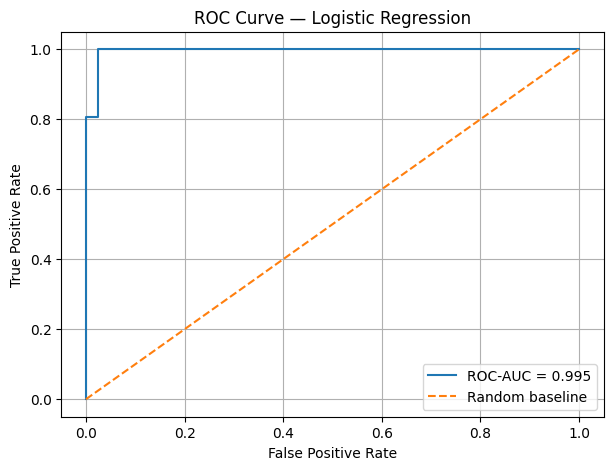

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_val, y_proba)
auc = roc_auc_score(y_val, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("Number of ROC thresholds:", len(thresholds))

for i in range(min(10, len(thresholds))):
    print(
        f"Threshold: {thresholds[i]:.4f}",
        f"FPR: {fpr[i]:.4f}",
        f"TPR: {tpr[i]:.4f}"
    )

Number of ROC thresholds: 6
Threshold: inf FPR: 0.0000 TPR: 0.0000
Threshold: 1.0000 FPR: 0.0000 TPR: 0.0139
Threshold: 0.9166 FPR: 0.0000 TPR: 0.8056
Threshold: 0.9087 FPR: 0.0238 TPR: 0.8056
Threshold: 0.3659 FPR: 0.0238 TPR: 1.0000
Threshold: 0.0000 FPR: 1.0000 TPR: 1.0000


In [ ]:
print(thresholds)

[           inf 9.99999580e-01 9.16588147e-01 9.08728148e-01
 3.65861856e-01 1.63299654e-23]


In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best hyperparameters:", search.best_params_)
print("Best mean CV ROC-AUC:", search.best_score_)

best_model = search.best_estimator_
test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)
print("Held-out test ROC-AUC:", test_auc)

Best hyperparameters: {'model__C': 1}
Best mean CV ROC-AUC: 0.9958720330237357
Held-out test ROC-AUC: 0.9953703703703703
